# Module 2 · Partie 0 : Introduction au module et présentation des données

**Analyse multivariée 2 : Data Mining & Machine Learning** — *Validation, PCR and PLS* (Prof. Hélène Soyeurt, année académique 2026-2027)

---

### Objectifs d'apprentissage
À la fin de ce notebook, tu sauras :
1. situer le module 2 dans le cours et expliquer **pourquoi** il prolonge directement le module 1 ;
2. citer les trois grands thèmes du module : **validation**, **régression sur composantes principales (PCR)** et **régression des moindres carrés partiels (PLS)** ;
3. lire correctement **tous les jeux de données** du module (acides gras, fichier de validation, sols NIR, exemple « octane ») et repérer leurs pièges (en-têtes, colonnes, valeurs manquantes codées 0) ;
4. représenter un ensemble de spectres avec `matplot()` ;
5. stocker une **matrice dans un data.frame**, la structure attendue par le package `pls` ;
6. résumer le contexte de l'article *Chimiométrie 2006*, dont proviennent les données du homework 2.

### Prérequis
Module 1 en entier, en particulier : régression multivariée, colinéarité, surapprentissage, régressions pénalisées (`glmnet`).

### Sommaire
- 0.1 Mode d'emploi et notebooks du module 2
- 0.2 Pourquoi un module 2 ? Du module 1 à la validation, la PCR et la PLS
- 0.3 Les packages du module
- 0.4 Jeu de données 1 : les acides gras du lait (calibration)
- 0.5 Jeu de données 2 : le fichier de validation externe
- 0.6 Jeu de données 3 : les sols en proche infrarouge (homework 2)
- 0.7 Jeu de données 4 : l'exemple « octane » du syllabus
- 0.8 Une matrice dans un data.frame : la structure du package `pls`
- 0.9 L'article *Chimiométrie 2006*
- Questions de compréhension
- Récapitulatif

## 0.1 Mode d'emploi et notebooks du module 2

| Notebook | Contenu |
|---|---|
| `00_Introduction_et_donnees` | Place du module, jeux de données, structure `pls`, article *Chimiométrie 2006* (**tu es ici**) |
| `01_Validation` | Validation interne et externe, taille du jeu d'apprentissage, validation croisée, indicateurs de performance |
| `02_ACP_et_detection_des_outliers_spectraux` | Rappels d'ACP, distance de Mahalanobis, distance GH, potentiel de prédiction |
| `03_Regression_sur_composantes_principales_PCR` | PCR pas à pas, package `pls`, choix du nombre de composantes |
| `04_Regression_PLS` | PLS, algorithme NIPALS, Q², T² de Hotelling, interprétation |
| `05_Comparaison_des_modeles_et_validation_externe` | PCR, PLS, Ridge, Lasso, Elastic Net sur un jeu de validation externe |
| `06_TP_Homework2_sols` | TP guidé : le homework 2 (azote total des sols) |
| `07_Synthese_et_aide_memoire` | Synthèse, workflow complet, aide-mémoire |

Rappels d'utilisation (identiques au module 1) :
- noyau **R (AM2)** dans VS Code, exécution avec **Shift + Entrée**, cellules à exécuter **dans l'ordre** ;
- encadrés **Définition**, **Attention**, **Complément** (pédagogie ajoutée au-delà du syllabus) et **Fonction R** ;
- exercices : une cellule `# À toi de jouer !`, puis une solution repliable « Voir la solution ».

Les données du module se trouvent dans le dossier parent `Module2/` : elles sont lues avec le préfixe `../`, car le dossier courant d'un notebook Jupyter est celui du notebook (`Module2/Cours/`).

In [1]:
# Packages et options utilisés dans ce notebook
suppressPackageStartupMessages({
  library(FactoMineR)   # ACP (PCA)
  library(pls)          # PCR et PLS
  library(knitr)        # kable() : tableaux lisibles
})
options(repr.plot.width = 10, repr.plot.height = 6)   # taille des figures (propre à Jupyter)
getwd()   # dossier courant = Module2/Cours

[1] "/home/teo/Documents/GBX/MA2/AM2/Module2/Cours"

## 0.2 Pourquoi un module 2 ? Du module 1 à la validation, la PCR et la PLS

### Ce que le module 1 a laissé en suspens
Le module 1 a buté sur trois problèmes, tous visibles avec les spectres moyen infrarouge du lait :

| Problème rencontré au module 1 | Ce qui se passait | Réponse du module 2 |
|---|---|---|
| **Surapprentissage** (*overfitting*) | Le R² de calibration augmente **toujours** quand on ajoute des variables ; on finit par expliquer une variabilité propre au jeu de données, pas générale. | **Validation** : mesurer la performance sur des données **non utilisées** pour construire le modèle (§1 du syllabus). |
| **Colinéarité** | Les points spectraux adjacents sont corrélés à plus de 0.9 : coefficients instables, non significatifs, interprétation impossible. | **Réduction de dimension** : remplacer les variables corrélées par des **composantes non corrélées** (PCR §2, PLS §3). |
| **n < p** | 178 (lactoferrine) ou 485 (acides gras) échantillons pour 1 060 variables : la régression classique est impossible, $X'X$ n'est pas inversible. | La PCR et la PLS travaillent sur **quelques composantes** au lieu des 1 060 variables. |

Au module 1, on a contourné ces problèmes par une **présélection** (les 10 points les plus corrélés), une **sélection de variables** (AIC) ou une **pénalisation** (Ridge, Lasso). Mais toutes les performances étaient des performances **de calibration**, donc optimistes.

### Le plan du syllabus *Validation, PCR and PLS*

1. **Validation** : validation interne vs externe, taille du jeu d'apprentissage, validation croisée.
2. **Principal Component Regression (PCR)** : introduction, méthodologie, avantages et inconvénients.
3. **Partial Least Squares regression (PLS)** : introduction, algorithme NIPALS, détection des valeurs anormales, pouvoir prédictif et explicatif des variables latentes, potentiel de prédiction, PLS pénalisée, avantages.

> **Définition** : la **calibration** (ou apprentissage, *training*, *learning*) est l'étape où l'on estime les paramètres d'un modèle ; la **validation** (ou test) est l'étape où l'on mesure ses performances sur d'autres données. Ce vocabulaire vient du processus KDD vu en partie 0 du module 1 (étape *Interpretation / Evaluation*).

## 0.3 Les packages du module

Deux nouveaux packages entrent en jeu :

| Package | Rôle dans le module | Fonctions principales |
|---|---|---|
| `FactoMineR` | Analyse en composantes principales (ACP, *PCA*) : détection des outliers spectraux (distance GH) | `PCA()`, `predict()` |
| `pls` | Régression sur composantes principales et PLS, avec validation croisée intégrée | `pcr()`, `plsr()`, `RMSEP()`, `R2()`, `validationplot()`, `predplot()`, `coefplot()`, `selectNcomp()`, `cvsegments()` |

On réutilise aussi `glmnet` (module 1, avec cette fois `cv.glmnet()` pour choisir λ par validation croisée), `summarytools`, `knitr`, ainsi que `reshape2` et `ggplot2`, qu'emploie la résolution officielle pour ses graphiques.

> **Attention** : au chargement, `pls` affiche « *The following object is masked from 'package:stats': loadings* ». Le package `pls` définit sa propre fonction `loadings()` qui remplace celle de base. Ce n'est pas une erreur. Dans ce notebook, le message est masqué par `suppressPackageStartupMessages()`.

In [2]:
# Vérifier que tous les packages du module sont installés
pkgs <- c("FactoMineR", "pls", "glmnet", "reshape2", "ggplot2", "summarytools", "knitr", "corrplot")
sapply(pkgs, function(p) p %in% rownames(installed.packages()))
packageVersion("pls"); packageVersion("FactoMineR")

FactoMineR          pls       glmnet     reshape2      ggplot2 summarytools 
        TRUE         TRUE         TRUE         TRUE         TRUE         TRUE 
       knitr     corrplot 
        TRUE         TRUE

[1] ‘2.9.0’

[1] ‘2.17’

## 0.4 Jeu de données 1 : les acides gras du lait (calibration)

C'est le même fichier qu'au homework 1 : **485 échantillons de lait**, la teneur en acides gras saturés (SAT), mono-insaturés (MONO) et polyinsaturés (POLY) en g/dl de lait, et **1 060 points spectraux** moyen infrarouge (MIR). Il sert à l'exercice dirigé officiel du module 2 (`PLS_PCR_fatty_acids_20201007.Rmd`) et à tes scripts `pca_`, `pcr_` et `pls_fatty_acids.R`.

Structure : colonne 1 = `sampleID`, 2 = `SAT`, 3 = `MONO`, 4 = `POLY`, colonnes 5 à 1064 = spectre.

In [3]:
# Lecture comme dans la résolution officielle : read.table avec en-tête
fattyacid <- read.table(file = "../fatty_acids.csv", sep = ";", header = TRUE)
dim(fattyacid)
names(fattyacid)[1:7]          # les colonnes spectrales "1", "2", ... deviennent "X1", "X2", ...
str(fattyacid, list.len = 6)   # list.len limite l'affichage aux 6 premières colonnes

[1]  485 1064

[1] "sampleID" "SAT"      "MONO"     "POLY"     "X1"       "X2"       "X3"

'data.frame':	485 obs. of  1064 variables:
 $ sampleID: int  1 2 3 4 5 6 7 8 9 10 ...
 $ SAT     : num  2.78 4.2 4.58 4.39 2.4 ...
 $ MONO    : num  1.27 1.83 1.47 1.35 2.01 ...
 $ POLY    : num  0.227 0.414 0.297 0.203 0.158 0.212 0.135 0.168 0.259 0.223 ...
 $ X1      : num  -0.0838 -0.1139 -0.1167 -0.098 -0.079 ...
 $ X2      : num  -0.0792 -0.1087 -0.1111 -0.0923 -0.0752 ...
  [list output truncated]


> **Attention** : les noms de colonnes numériques (`1`, `2`, …) ne sont pas des noms R valides : `read.table()` et `read.csv()` les transforment en `X1`, `X2`, … (argument `check.names = TRUE` par défaut). Tes scripts `pca_fatty_acids.R` et `pls_fatty_acids.R` utilisent `read.csv(sep = ";", check.names = FALSE)` pour garder les noms d'origine. Les deux sont corrects, mais il faut rester cohérent quand on désigne une colonne par son nom.

In [4]:
# Lecture comme dans tes scripts : read.csv en gardant les noms d'origine
fa <- read.csv("../fatty_acids.csv", sep = ";", check.names = FALSE)
names(fa)[1:7]
# read.csv() = read.table() avec header = TRUE, sep = "," et dec = "." par défaut :
# on précise sep = ";" ; read.csv2() supposerait en plus dec = ",", ce qui serait faux ici
identical(unname(as.matrix(fa[, -1])), unname(as.matrix(fattyacid[, -1])))

[1] "sampleID" "SAT"      "MONO"     "POLY"     "1"        "2"        "3"

[1] TRUE

> **Fonction R** : `read.table(file, header = FALSE, sep = "", dec = ".", check.names = TRUE, ...)`
>
> | Argument | Rôle |
> |---|---|
> | `file` | chemin du fichier (relatif au dossier courant) |
> | `header` | `TRUE` si la première ligne contient les noms des colonnes |
> | `sep` | séparateur de colonnes (`";"` dans tous les fichiers du module) |
> | `dec` | séparateur décimal (`"."` ici) |
> | `check.names` | `TRUE` : rend les noms valides en R (`1` → `X1`) |
>
> Renvoie un `data.frame`. Variantes : `read.csv()` (`header = TRUE`, `sep = ","`), `read.csv2()` (`sep = ";"`, `dec = ","`).

In [5]:
# Séparer la variable à expliquer et la matrice spectrale (comme dans la résolution)
x <- fattyacid[, 5:1064]   # spectre : colonnes 5 à 1064
y <- fattyacid[, 2]        # SAT : 2e colonne
c(n = nrow(x), p = ncol(x))
summary(y)

n    p 
 485 1060

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  0.188   1.850   2.151   2.403   2.811   5.489 

### Représenter tous les spectres : `matplot()`

Un spectre est une **ligne** de la matrice `x`. Pour les superposer, on utilise `matplot()`, qui trace **chaque colonne** d'une matrice comme une courbe : il faut donc **transposer** la matrice avec `t()` pour que chaque échantillon devienne une colonne.

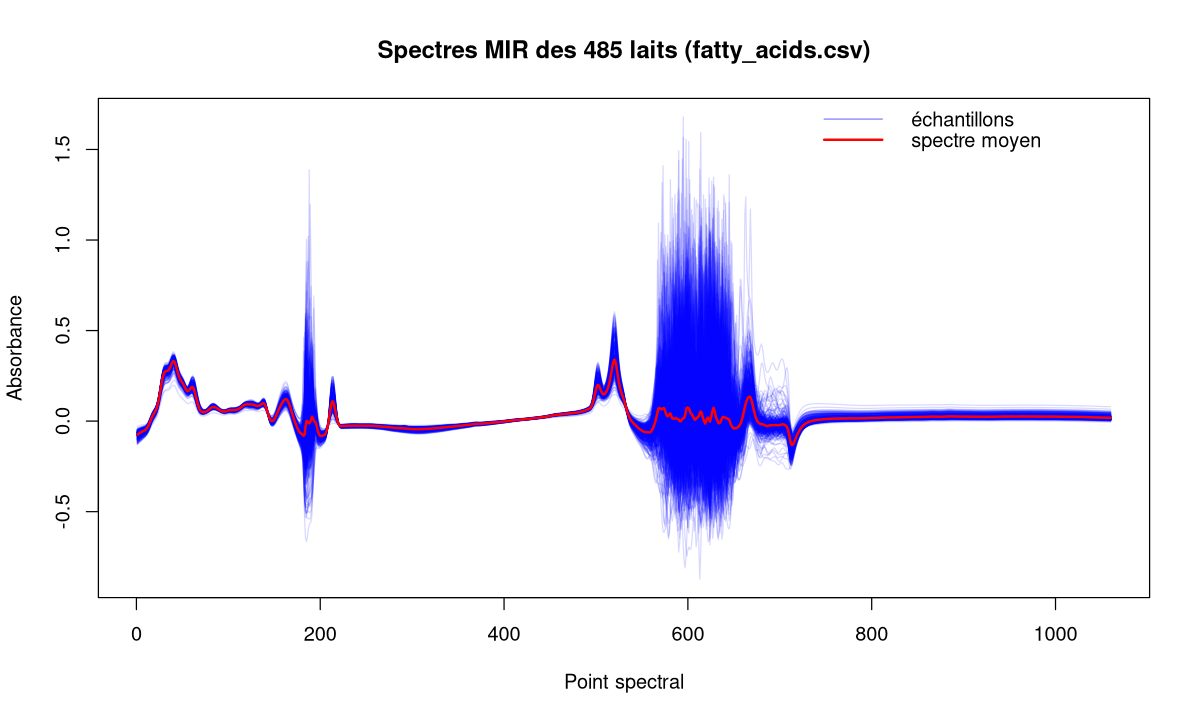

In [6]:
matplot(t(x), type = "l", lty = 1, col = rgb(0, 0, 1, 0.15),
        xlab = "Point spectral", ylab = "Absorbance",
        main = "Spectres MIR des 485 laits (fatty_acids.csv)")
lines(colMeans(x), col = "red", lwd = 2)   # spectre moyen
legend("topright", legend = c("échantillons", "spectre moyen"),
       col = c(rgb(0, 0, 1, 0.5), "red"), lty = 1, lwd = c(1, 2), bty = "n")

> **Fonction R** : `matplot(x, y, type = "p", lty, col, xlab, ylab, main, ...)`
>
> Trace les **colonnes** de `y` en fonction de `x` (ou de leur indice si `x` est omis). `type = "l"` pour des lignes, `lty = 1` pour des traits pleins, `col = rgb(r, g, b, alpha)` pour des couleurs transparentes, utiles quand des centaines de courbes se superposent. Pour des spectres stockés en lignes : `matplot(longueurs_d_onde, t(X), type = "l")`.

### Exercice 0.1 : statistiques descriptives des trois acides gras
Calcule la moyenne, l'écart-type, le minimum et le maximum de `SAT`, `MONO` et `POLY` dans `fattyacid`, en une seule instruction avec `sapply()`. Lequel des trois est le plus variable en valeur relative (coefficient de variation) ?

In [7]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
stats <- sapply(fattyacid[, c("SAT", "MONO", "POLY")], function(v)
  c(moyenne = mean(v), ecart_type = sd(v), min = min(v), max = max(v),
    CV_pct = 100 * sd(v) / mean(v)))
round(stats, 3)
```

`sapply()` applique la fonction à chaque colonne et rassemble les résultats dans une matrice (une colonne par acide gras). Le coefficient de variation permet de comparer des variables de moyennes différentes : SAT a la plus forte moyenne, mais c'est POLY qui varie le plus en valeur relative.

</details>

## 0.5 Jeu de données 2 : le fichier de validation externe

La résolution officielle (section 6) dispose d'un second fichier, `validation_fatty_acids.csv`, qui contient **338 autres échantillons** de lait. Il n'a servi ni à construire ni à paramétrer les modèles : c'est un **jeu de validation externe** (on en verra l'intérêt en partie 1).

In [8]:
validation <- read.table(file = "../validation_fatty_acids.csv", sep = ";", header = TRUE)
dim(validation)
names(validation)[1:4]
names(validation)[c(1:3, ncol(validation))]

[1]  338 1062

[1] "SampleID" "SAT"      "X1"       "X2"

[1] "SampleID" "SAT"      "X1"       "X1060"

> **Attention** : ce fichier n'a **pas la même structure** que `fatty_acids.csv`. Il ne contient que `SampleID` et `SAT` (ni MONO, ni POLY), donc le spectre occupe les colonnes **3 à 1062** et non 5 à 1064. La résolution le gère avec `validation[, 3:1062]`. Reprendre les indices du fichier de calibration donnerait un spectre décalé de deux colonnes, **sans aucun message d'erreur**. De plus, la première colonne s'appelle `SampleID` (S majuscule) et non `sampleID`.

In [9]:
validy       <- validation[, 2]         # SAT
validspectra <- validation[, 3:1062]    # spectre
# Contrôle : le nombre de colonnes spectrales doit être identique dans les deux fichiers
c(calibration = ncol(x), validation = ncol(validspectra))
# Les distributions de SAT sont-elles comparables ?
round(rbind(calibration = summary(y), validation = summary(validy)), 3)

calibration  validation 
       1060        1060

,Min.,1st Qu.,Median,Mean,3rd Qu.,Max.
calibration,0.188,1.850,2.151,2.403,2.811,5.489
validation,0.443,2.295,2.684,2.754,3.133,6.186


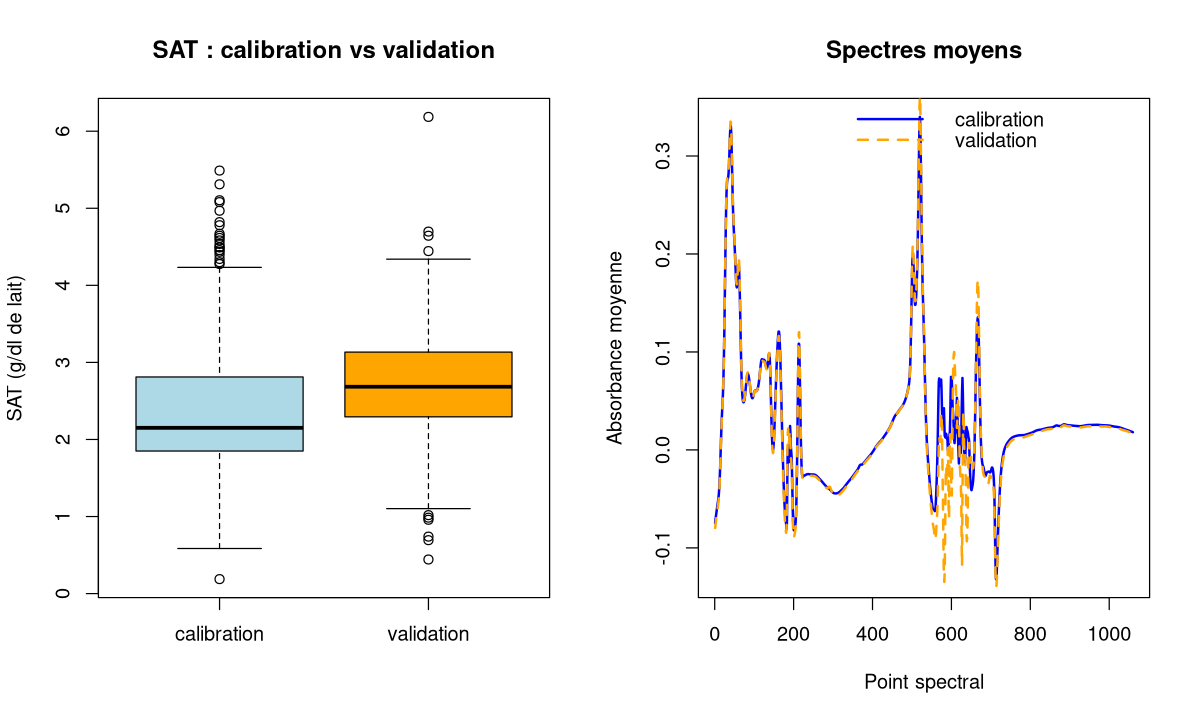

In [10]:
par(mfrow = c(1, 2))
boxplot(list(calibration = y, validation = validy), col = c("lightblue", "orange"),
        ylab = "SAT (g/dl de lait)", main = "SAT : calibration vs validation")
plot(colMeans(x), type = "l", col = "blue", lwd = 2, xlab = "Point spectral",
     ylab = "Absorbance moyenne", main = "Spectres moyens")
lines(colMeans(validspectra), col = "orange", lwd = 2, lty = 2)
legend("topright", c("calibration", "validation"), col = c("blue", "orange"),
       lty = c(1, 2), lwd = 2, bty = "n")
par(mfrow = c(1, 1))

Les spectres moyens se superposent, mais la teneur moyenne en SAT est **plus élevée** dans le fichier de validation (2.75 contre 2.40 g/dl). Un jeu de validation n'a pas forcément exactement la même distribution que le jeu de calibration : c'est justement ce qui permet de tester la **capacité de généralisation** du modèle. Garde cette différence en tête pour interpréter les résultats de la partie 5.

### Exercice 0.2 : contrôle de cohérence des deux fichiers
Vérifie que les **noms** des colonnes spectrales sont identiques dans `x` et `validspectra` (fonction `identical()` sur `names()`). Compte ensuite combien d'échantillons du fichier de validation ont une teneur en SAT **supérieure au maximum** du fichier de calibration.

In [11]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
identical(names(x), names(validspectra))   # TRUE : X1 ... X1060 dans les deux fichiers
sum(validy > max(y))                       # échantillons hors de la gamme de calibration
validy[validy > max(y)]
```

Un échantillon dont la valeur de référence dépasse la gamme de calibration oblige le modèle à **extrapoler** : sa prédiction sera souvent moins bonne. C'est l'idée du « potentiel de prédiction » (§3.5 du syllabus) que l'on retrouvera avec la distance GH en partie 2.

</details>

## 0.6 Jeu de données 3 : les sols en proche infrarouge (homework 2)

Énoncé du homework 2 (*Prediction of Soil Characteristics from Near Infrared Spectrometry*) : **618 spectres de réflectance** proche infrarouge (NIR) mesurés sur des sols cultivés, tamisés et séchés, prélevés dans différentes localités de Wallonie, entre **1 100 et 2 498 nm** avec un pas de **2 nm** (soit 700 longueurs d'onde). Trois paramètres physico-chimiques ont été mesurés par des méthodes de référence :
- l'**azote total** (*total nitrogen*, Nt ; g/kg de sol sec) ;
- la **capacité d'échange cationique** (*Cation Exchange Capacity*, CEC ; meq/100 g de sol sec) ;
- la teneur en **carbone** (C ; % du sol sec).

Objectif du homework : construire la **meilleure équation de prédiction de Nt**, et rendre l'objet R correspondant avec `save()`.

| Fichier | Contenu | Dimensions |
|---|---|---|
| `Xcal.txt` | spectres de calibration, avec en-tête (longueurs d'onde) | 618 × 700 |
| `Ycal.txt` | valeurs de référence, **sans** en-tête ; **0 = donnée manquante** | 618 × 3 |
| `Xtest.txt` | spectres du jeu de test | 207 × 700 |
| `Ytest.txt` | valeurs de référence du test (fournies ici, mais pas dans le concours d'origine) | 207 × 3 |

In [12]:
Xcal  <- read.table(file = "../Xcal.txt",  sep = ";", header = TRUE)
Ycal  <- read.table(file = "../Ycal.txt",  sep = ";", header = FALSE)
Xtest <- read.table(file = "../Xtest.txt", sep = ";", header = TRUE)
Ytest <- read.table(file = "../Ytest.txt", sep = ";", header = FALSE)
sapply(list(Xcal = Xcal, Ycal = Ycal, Xtest = Xtest, Ytest = Ytest), dim)
names(Xcal)[1:4]   # "1100.00000" est devenu "X1100.00000"
head(Ycal, 4)

Xcal,Ycal,Xtest,Ytest
618,618,207,207
700,3,700,3


[1] "X1100.00000" "X1102.00000" "X1104.00000" "X1106.00000"

,V1,V2,V3
,<dbl>,<dbl>,<dbl>
1,0.30,0.22,0
2,0.69,0.00,0
3,0.71,0.00,0
4,0.85,0.00,0


Les noms de colonnes de `Xcal` contiennent les longueurs d'onde. On peut soit les reconstruire (`seq(1100, 2498, by = 2)`, comme dans ton `homework2.R`), soit les extraire des noms : les deux doivent coïncider.

[1] 700

[1] TRUE

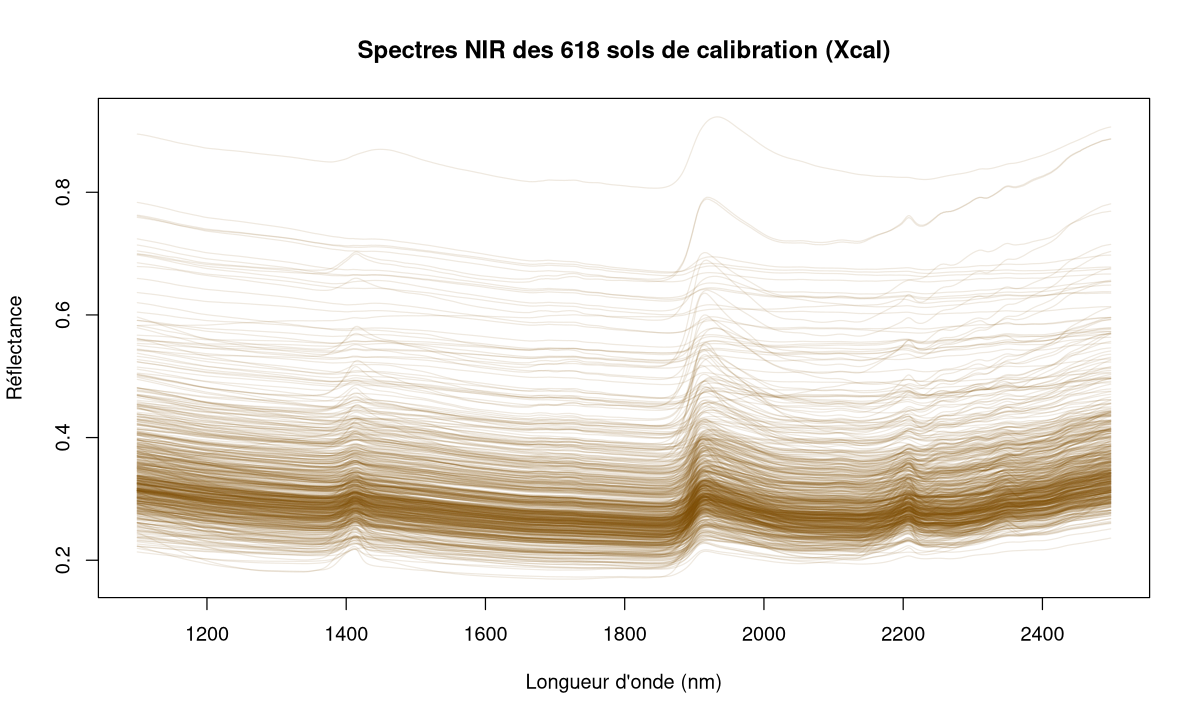

In [13]:
wavelength <- seq(1100, 2498, by = 2)
wl_noms <- as.numeric(sub("^X", "", names(Xcal)))   # retire le "X" ajouté par check.names
length(wavelength); all.equal(wavelength, wl_noms)

matplot(wavelength, t(Xcal), type = "l", lty = 1, col = rgb(0.5, 0.3, 0, 0.12),
        xlab = "Longueur d'onde (nm)", ylab = "Réflectance",
        main = "Spectres NIR des 618 sols de calibration (Xcal)")

### Les valeurs manquantes codées 0

Dans `Ycal` et `Ytest`, une valeur **0** signifie « pas de valeur de référence » : un sol ne contient jamais 0 g/kg d'azote. Il faut donc **retirer ces lignes** avant toute modélisation, et **en même temps** dans X et dans y pour garder l'alignement des échantillons.

In [14]:
# Pourcentage de valeurs manquantes par colonne de Ycal et nombre de valeurs disponibles
manquants <- rbind(n_manquants_cal  = colSums(Ycal == 0),
                   pct_manquants_cal = round(100 * colMeans(Ycal == 0), 1),
                   n_disponibles_cal = colSums(Ycal > 0),
                   n_disponibles_test = colSums(Ytest > 0))
manquants

,V1,V2,V3
n_manquants_cal,133.0,70.0,284
pct_manquants_cal,21.5,11.3,46
n_disponibles_cal,485.0,548.0,334
n_disponibles_test,160.0,184.0,113


> **Attention** (incohérence entre les sources) : l'énoncé du homework annonce que `Ycal` contient « Nt, CEC and C », dans cet ordre. Or l'article *Chimiométrie 2006* indique **22 %** de valeurs manquantes pour Nt, **11 %** pour C et **46 %** pour CEC, et respectivement **160**, **184** et **113** valeurs dans le jeu de test. Les pourcentages calculés ci-dessus (21.5 %, 11.3 %, 46.0 %) et les effectifs du test (160, 184, 113) montrent que l'ordre réel des colonnes est **Nt, C, CEC**. Pour le homework, cela ne change rien : Nt est bien la **première** colonne.

[1] 485 701

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  0.200   1.100   1.300   1.776   2.000   8.100 

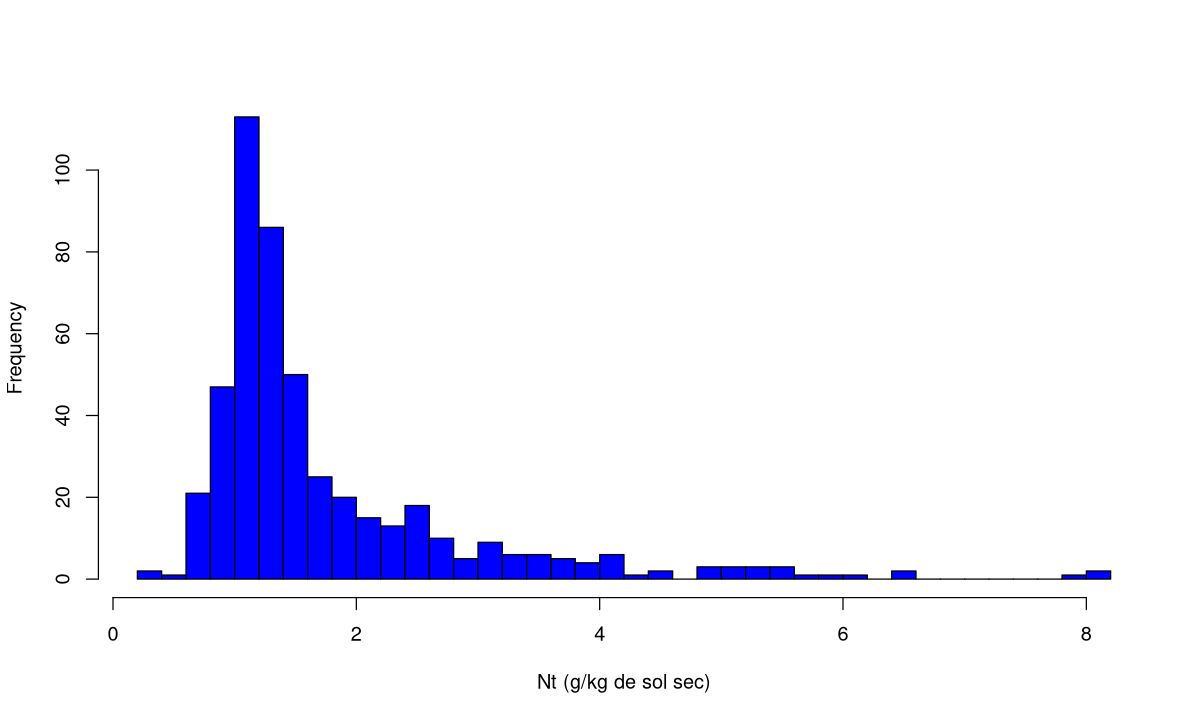

In [15]:
# Jeu de calibration pour Nt : on ne garde que les échantillons avec une valeur de référence
ok   <- Ycal[, 1] > 0
cal  <- data.frame(Nt = Ycal[ok, 1], Xcal[ok, ])
dim(cal)
summary(cal$Nt)
hist(cal$Nt, breaks = 30, col = "blue", xlab = "Nt (g/kg de sol sec)", main = NULL)

La distribution de Nt est fortement **asymétrique à droite** (moyenne 1.78 > médiane 1.30, maximum 8.1). Les quelques sols très riches en azote seront difficiles à prédire : on y reviendra dans le TP (partie 6).

### Exercice 0.3 : préparer le jeu de test
En t'inspirant de la cellule précédente, crée un data.frame `test` qui contient la colonne `Nt` (première colonne de `Ytest`) et les spectres de `Xtest`, **uniquement** pour les échantillons dont Nt est disponible. Vérifie qu'il compte 160 lignes et compare le résumé de Nt avec celui de la calibration.

In [16]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
ok_test <- Ytest[, 1] > 0
test <- data.frame(Nt = Ytest[ok_test, 1], Xtest[ok_test, ])
nrow(test)                                   # 160
round(rbind(calibration = summary(cal$Nt), test = summary(test$Nt)), 2)
```

Le filtre logique `ok_test` est appliqué **à la fois** aux lignes de `Ytest` et de `Xtest` : c'est ce qui garantit que chaque spectre reste associé à sa valeur de référence.

</details>

### Exercice 0.4 : spectre moyen, minimum et maximum des sols
Trace, en fonction de la longueur d'onde, le spectre moyen de `Xcal` ainsi que les spectres minimum et maximum point par point (fonctions `colMeans()` et `apply(..., 2, min)`). Ajoute une légende.

In [17]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
m  <- colMeans(Xcal)
mn <- apply(Xcal, 2, min)
mx <- apply(Xcal, 2, max)
plot(wavelength, m, type = "l", lwd = 2, ylim = range(mn, mx),
     xlab = "Longueur d'onde (nm)", ylab = "Réflectance")
lines(wavelength, mn, col = "blue")
lines(wavelength, mx, col = "green4")
legend("topleft", c("moyenne", "minimum", "maximum"), col = c("black", "blue", "green4"),
       lty = 1, lwd = c(2, 1, 1), bty = "n")
```

`apply(X, 2, f)` applique `f` à chaque **colonne** (2) de `X` ; avec `1`, ce serait à chaque ligne. C'est la même démarche que la correction officielle du homework 1 (spectre moyen, min et max avec `descr()`), en plus direct.

</details>

## 0.7 Jeu de données 4 : l'exemple « octane » du syllabus

Tout le chapitre PCR/PLS du syllabus repose sur un petit exemple : l'**indice d'octane** (y) de **12 mélanges** de carburant, expliqué par la proportion de **7 composants** (x1 à x7, Table 1). Ces données ne sont pas fournies dans un fichier : on les saisit à la main. Ce petit jeu permettra de refaire **tous les calculs du syllabus** (parties 3 et 4) et de les comparer aux tables publiées.

In [18]:
# Table 1 du syllabus : 12 mélanges, 7 composants, indice d'octane
octane <- data.frame(
  x1 = c(0, 0, 0, 0, 0, 0, 0.17, 0.17, 0.17, 0.17, 0.21, 0),
  x2 = c(0.23, 0.1, 0, 0.49, 0, 0.62, 0.27, 0.19, 0.21, 0.15, 0.36, 0),
  x3 = c(0, 0, 0, 0, 0, 0, 0.1, 0.1, 0.1, 0.1, 0.12, 0),
  x4 = c(0, 0, 0.1, 0, 0.62, 0, 0.38, 0.38, 0.38, 0.38, 0.25, 0.55),
  x5 = c(0, 0.12, 0.12, 0.12, 0.12, 0, 0, 0.02, 0, 0.02, 0, 0),
  x6 = c(0.74, 0.74, 0.74, 0.37, 0.18, 0.37, 0, 0.06, 0.06, 0.1, 0, 0.37),
  x7 = c(0.03, 0.04, 0.04, 0.02, 0.08, 0.01, 0.08, 0.08, 0.08, 0.08, 0.06, 0.08),
  octane = c(98.7, 97.8, 96.6, 92, 86.6, 91.2, 81.9, 83.1, 82.4, 83.2, 81.4, 88.1))
octane

x1,x2,x3,x4,x5,x6,x7,octane
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0.00,0.23,0.00,0.00,0.00,0.74,0.03,98.7
0.00,0.10,0.00,0.00,0.12,0.74,0.04,97.8
0.00,0.00,0.00,0.10,0.12,0.74,0.04,96.6
0.00,0.49,0.00,0.00,0.12,0.37,0.02,92.0
0.00,0.00,0.00,0.62,0.12,0.18,0.08,86.6
0.00,0.62,0.00,0.00,0.00,0.37,0.01,91.2
0.17,0.27,0.10,0.38,0.00,0.00,0.08,81.9
0.17,0.19,0.10,0.38,0.02,0.06,0.08,83.1
0.17,0.21,0.10,0.38,0.00,0.06,0.08,82.4


In [19]:
# Matrice de corrélation entre les variables explicatives (à comparer au §2.1 du syllabus)
round(cor(octane[, 1:7]), 2)

,x1,x2,x3,x4,x5,x6,x7
x1,1.00,0.10,1.00,0.37,-0.55,-0.80,0.60
x2,0.10,1.00,0.10,-0.54,-0.29,-0.19,-0.59
x3,1.00,0.10,1.00,0.37,-0.55,-0.81,0.61
x4,0.37,-0.54,0.37,1.00,-0.21,-0.65,0.92
x5,-0.55,-0.29,-0.55,-0.21,1.00,0.46,-0.27
x6,-0.80,-0.19,-0.81,-0.65,0.46,1.00,-0.66
x7,0.60,-0.59,0.61,0.92,-0.27,-0.66,1.00


On retrouve la matrice du syllabus : **x1 et x3 sont corrélés à 1.00**, x4 et x7 à 0.92, x1 et x6 à −0.80. Il y a donc une forte **colinéarité** : avec 12 observations et 7 variables quasi redondantes, la régression multiple classique donnerait des coefficients instables. C'est exactement la situation pour laquelle la PCR et la PLS ont été conçues.

> **Complément** : chaque ligne est un mélange, donc les 7 proportions somment à 1 (vérifie-le avec `rowSums(octane[, 1:7])`). Par ailleurs, x1 et x3 sont presque proportionnels (x3 ≈ 0.58 × x1 sur toutes les lignes) : leur corrélation vaut 0.9999, arrondie à 1.00. Ce n'est pas une colinéarité **parfaite**, mais c'en est très proche.

### Exercice 0.5 : la colinéarité de l'octane en action
Ajuste la régression linéaire multiple classique `lm(octane ~ ., data = octane)` et affiche son `summary()`. Combien de coefficients sont significatifs au seuil de 5 % ? Compare avec le R² obtenu.

In [20]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
reg_octane <- lm(octane ~ ., data = octane)
summary(reg_octane)
```

Le R² est très élevé (0.9925, soit les 99.3 % de la Table 2 du syllabus pour 7 composantes), mais **aucun coefficient n'est significatif** (toutes les p-values > 0.2) et les erreurs standard sont énormes : c'est le symptôme typique de la colinéarité vu au module 1 (partie 3). De plus, le coefficient de **x7 vaut `NA`** (« 1 not defined because of singularities ») : les 7 composants sont des **proportions d'un mélange**, donc leur somme vaut 1 sur chaque ligne (`rowSums(octane[, 1:7])`). Une variable est alors une combinaison linéaire exacte de l'intercept et des 6 autres : c'est la **colinéarité parfaite**, exactement comme les acides gras dont la somme vaut 100 % au module 1 (partie 3). Avec seulement 5 degrés de liberté résiduels, le modèle est en outre à la limite du surapprentissage. La PCR et la PLS résoudront ce problème en régressant y sur quelques **composantes non corrélées**.

</details>

## 0.8 Une matrice dans un data.frame : la structure du package `pls`

Les fonctions `pcr()` et `plsr()` s'utilisent avec une **formule**, comme `lm()`. Deux écritures sont possibles pour des données spectrales.

**Écriture 1 (résolution officielle)** : un data.frame « plat », une colonne par point spectral, et la formule `SAT ~ .` (« toutes les autres colonnes »).

**Écriture 2 (tes scripts `pcr_` et `pls_fatty_acids.R`)** : un data.frame à **deux colonnes**, dont la seconde est elle-même une **matrice** de 1 060 colonnes ; la formule devient `SAT ~ spectra`.

In [21]:
# Écriture 1 : data.frame plat avec des noms de colonnes explicites (comme la résolution)
calibration <- data.frame(y, x)
names(calibration) <- c("SAT", paste0("SPEC", 1:1060))
dim(calibration)
names(calibration)[1:4]

# Écriture 2 : la matrice spectrale stockée comme UNE colonne du data.frame
dat <- data.frame(SAT = y)
dat$spectra <- as.matrix(x)
dim(dat)            # 485 lignes, 2 "colonnes"
dim(dat$spectra)    # mais la 2e est une matrice 485 x 1060
str(dat, vec.len = 2)

[1]  485 1061

[1] "SAT"   "SPEC1" "SPEC2" "SPEC3"

[1] 485   2

[1]  485 1060

'data.frame':	485 obs. of  2 variables:
 $ SAT    : num  2.78 4.2 ...
 $ spectra: num [1:485, 1:1060] -0.0838 -0.1139 ...
  ..- attr(*, "dimnames")=List of 2
  .. ..$ : NULL
  .. ..$ : chr [1:1060] "X1" "X2" ...


> **Complément** : on peut aussi écrire `data.frame(SAT = y, spectra = I(as.matrix(x)))`. La fonction `I()` (« as is ») empêche `data.frame()` d'éclater la matrice en 1 060 colonnes. L'affectation `dat$spectra <- ...` produit le même résultat sans `I()`.

L'écriture 2 a deux avantages : la formule reste courte (`SAT ~ spectra`), et on peut tracer ou indexer le spectre d'un bloc (`dat$spectra[1:5, ]`). L'écriture 1 a l'avantage de ressembler à `lm()` et de fonctionner avec la plupart des autres fonctions. Les deux donnent **exactement le même modèle**, comme le montre l'exemple ci-dessous (on anticipe sur la partie 3).

In [22]:
m1 <- pcr(SAT ~ ., data = calibration, scale = TRUE, ncomp = 5)
m2 <- pcr(SAT ~ spectra, data = dat, scale = TRUE, ncomp = 5)
# Mêmes valeurs ajustées avec 5 composantes ?
all.equal(unname(fitted(m1)[, 1, 5]), unname(fitted(m2)[, 1, 5]))

[1] TRUE

> **Attention** : pour **prédire** de nouveaux échantillons avec `predict(modele, newdata = ...)`, le data.frame `newdata` doit avoir **la même structure** que celui de la calibration : mêmes noms de colonnes (`SPEC1` … `SPEC1060`) pour l'écriture 1, ou une colonne-matrice `spectra` pour l'écriture 2. C'est pourquoi la résolution renomme les colonnes du fichier de validation en `SPEC1` … `SPEC1060` avant de prédire.

### Exercice 0.6 : préparer le fichier de validation pour la prédiction
Construis, pour le fichier de validation, les deux structures compatibles avec `m1` et `m2` : un data.frame plat `valid1` avec les colonnes `SPEC1` … `SPEC1060`, et un data.frame `valid2` avec une colonne-matrice `spectra`. Prédis ensuite SAT avec 5 composantes par `predict(m1, newdata = valid1, ncomp = 5)` et `predict(m2, newdata = valid2, ncomp = 5)`, et vérifie que les deux prédictions sont identiques.

In [23]:
# À toi de jouer !

<details>
<summary><b>Voir la solution</b></summary>

```r
valid1 <- validspectra
names(valid1) <- paste0("SPEC", 1:1060)
valid2 <- data.frame(SAT = validy)
valid2$spectra <- as.matrix(validspectra)

p1 <- predict(m1, newdata = valid1, ncomp = 5)
p2 <- predict(m2, newdata = valid2, ncomp = 5)
dim(p1)                      # 338 x 1 x 1 : un tableau à 3 dimensions
all.equal(c(p1), c(p2))      # TRUE
```

`predict()` renvoie un **tableau à trois dimensions** (échantillons × réponses × nombre de composantes) ; `c()` l'aplatit en vecteur. On détaillera cette structure en partie 3.

</details>

## 0.9 L'article *Chimiométrie 2006*

Les données de sols du homework 2 ne sont pas inventées : elles ont fait l'objet d'un **concours de chimiométrie** organisé lors du congrès *Chimiométrie 2006* (Paris, 30 novembre et 1er décembre 2006). L'article de **J.A. Fernández Pierna et P. Dardenne** (CRA-W, Gembloux), *Soil parameter quantification by NIRS as a Chemometric challenge at 'Chimiométrie 2006'*, *Chemometrics and Intelligent Laboratory Systems* 91 (2008) 94–98, en résume l'organisation et les résultats.

### Les données du concours
- 618 spectres de réflectance de sols séchés et tamisés (calibration), 207 spectres de test, de 1 100 à 2 498 nm par pas de 2 nm ; sols cultivés de toute la Wallonie.
- Trois paramètres : **Nt** (azote total, g/kg), **CEC** (meq/100 g) et **Ciso** (carbone, % ; « iso » car dosé selon la méthode ISO 14235).
- Des **0** dans la matrice y correspondent à des valeurs manquantes, à ne pas utiliser en calibration : 22 % pour Nt, 11 % pour Ciso, 46 % pour CEC. Le test final contient 160 valeurs pour Nt, 184 pour Ciso et 113 pour CEC.
- Les valeurs de référence du test étaient **gardées par le jury** : les participants envoyaient leurs prédictions « à l'aveugle ». Pour le cours, `Ytest.txt` est fourni.
- Contrairement aux concours précédents, les données n'ont **pas été modifiées** par les organisateurs.

### Les approches des participants et des auteurs

| Qui | Prétraitement | Valeurs manquantes / outliers | Méthode de régression |
|---|---|---|---|
| Participant 1 | SNV + *detrend* + dérivée seconde | imputation multiple (logiciel NORM, 20 valeurs simulées par donnée manquante) ; échantillons de test à GH élevé signalés | régression LOCAL (WinISI), moyenne des 20 modèles |
| Participant 2 | *Multiple Scatter Correction* (MSC) + autoscaling | ACP pour détecter les outliers (4 échantillons retirés) ; manquants éliminés | réseau de neurones (rétropropagation) sur les 20 premières CP |
| Participant 3 | spectres « blanchis » (centrés-réduits) | outliers détectés et retirés | projection sur une base de B-splines, sélection par information mutuelle, réseaux RBF, CV à 8 segments |
| Auteurs | — | — | PLS, LOCAL (WinISI), LS-SVM |

> **Définition** : la régression **LOCAL** construit, pour **chaque** échantillon à prédire, un modèle PLS sur ses plus proches voisins dans une bibliothèque de spectres (similarité = corrélation entre spectres), à condition que les distances **GH < 3** et **NH < 1** soient acceptables. On retrouve ici la distance GH que l'on étudiera en partie 2.

In [24]:
# Table 1 de l'article : résultats du concours (RMSEP et R² sur le jeu de test)
concours <- data.frame(
  methode  = c("P1 Norm+LOCAL", "P2 Backprop. NN", "P3 B-splines+RBFN",
               "Auteurs PLS", "Auteurs LOCAL", "Auteurs LS-SVM"),
  RMSEP_Nt  = c(0.6537, 0.7737, 0.9655, 0.8404, 0.5853, 0.5575),
  RMSEP_C   = c(0.5577, 0.7755, 1.4846, 1.1476, 0.4332, 0.559),
  RMSEP_CEC = c(3.5826, 4.6235, 5.3609, 4.6051, 3.3328, 3.4373),
  R2_Nt     = c(0.7673, 0.63, 0.438, 0.5632, 0.7979, 0.8172),
  R2_C      = c(0.8702, 0.77, 0.5338, 0.496, 0.9216, 0.8908),
  R2_CEC    = c(0.7148, 0.51, 0.3474, 0.5087, 0.7508, 0.7294))
concours$R2_moyen <- round(rowMeans(concours[, c("R2_Nt", "R2_C", "R2_CEC")]), 2)
kable(concours, digits = 4)



|methode           | RMSEP_Nt| RMSEP_C| RMSEP_CEC|  R2_Nt|   R2_C| R2_CEC| R2_moyen|
|:-----------------|--------:|-------:|---------:|------:|------:|------:|--------:|
|P1 Norm+LOCAL     |   0.6537|  0.5577|    3.5826| 0.7673| 0.8702| 0.7148|     0.78|
|P2 Backprop. NN   |   0.7737|  0.7755|    4.6235| 0.6300| 0.7700| 0.5100|     0.64|
|P3 B-splines+RBFN |   0.9655|  1.4846|    5.3609| 0.4380| 0.5338| 0.3474|     0.44|
|Auteurs PLS       |   0.8404|  1.1476|    4.6051| 0.5632| 0.4960| 0.5087|     0.52|
|Auteurs LOCAL     |   0.5853|  0.4332|    3.3328| 0.7979| 0.9216| 0.7508|     0.82|
|Auteurs LS-SVM    |   0.5575|  0.5590|    3.4373| 0.8172| 0.8908| 0.7294|     0.81|

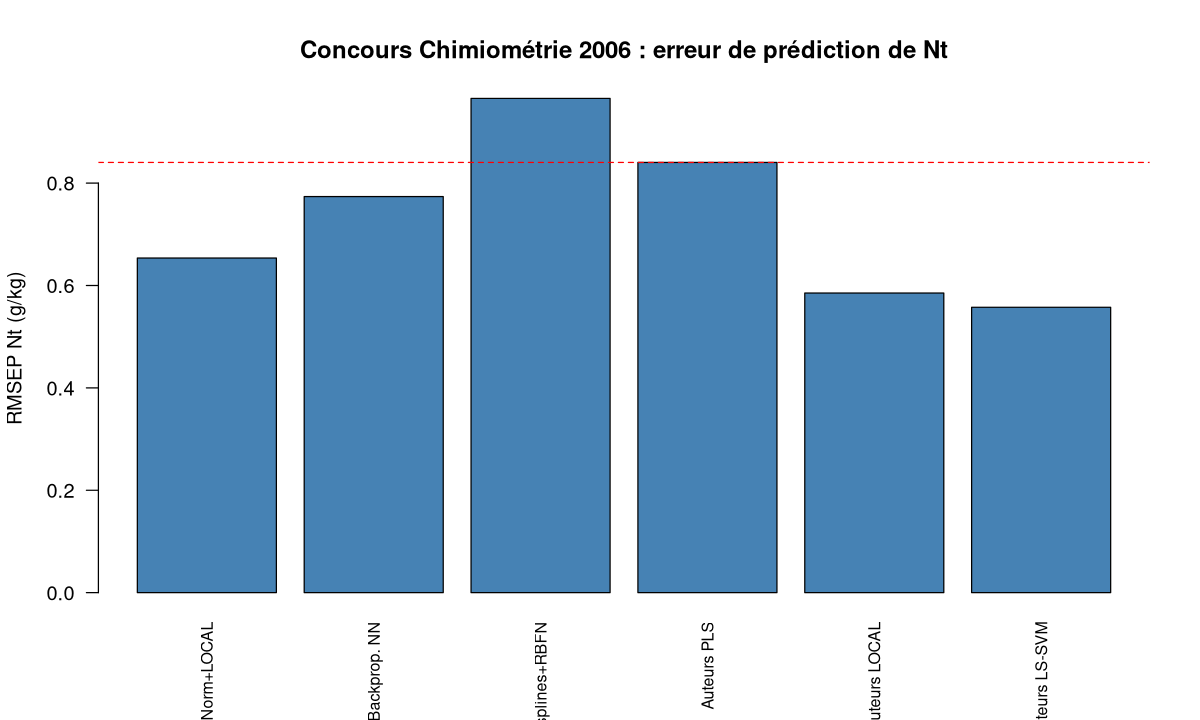

In [25]:
barplot(concours$RMSEP_Nt, names.arg = concours$methode, las = 2, col = "steelblue",
        ylab = "RMSEP Nt (g/kg)", main = "Concours Chimiométrie 2006 : erreur de prédiction de Nt",
        cex.names = 0.8)
abline(h = concours$RMSEP_Nt[concours$methode == "Auteurs PLS"], lty = 2, col = "red")

**Ce qu'il faut retenir de l'article**
- Pour Nt, la **PLS globale** des auteurs obtient un RMSEP de **0.84 g/kg** (R² 0.56), alors que les méthodes **locales** ou non linéaires (LOCAL 0.59, LS-SVM 0.56) font nettement mieux. C'est la référence à laquelle tu pourras comparer ton équation du homework 2.
- La diversité minérale des sols et leur faible teneur en matière organique rendent ces prédictions difficiles : seuls trois participants ont osé présenter leurs résultats.
- Les auteurs concluent à l'intérêt des méthodes locales, mais aussi au besoin de **bases de données plus grandes**, rassemblées au niveau international avec des méthodes de référence alignées.

> **Complément** : les prétraitements cités (**SNV**, *Standard Normal Variate* : centrer-réduire **chaque spectre** ; **MSC**, *Multiplicative Scatter Correction* ; **dérivées**) servent à corriger les effets de diffusion de la lumière, très présents en réflectance sur des poudres comme les sols. Ils ne font pas partie du syllabus du module 2 ; le TP (partie 6) en propose un essai rapide avec la SNV.

## Questions de compréhension

**Q1.** Pourquoi les performances obtenues au module 1 (R² de 0.99 sur les acides gras, par exemple) ne suffisent-elles pas à juger un modèle ?

**Q2.** Vrai ou faux : dans `Ycal.txt`, une teneur en azote égale à 0 signifie que le sol ne contient pas d'azote.

**Q3.** Dans `validation_fatty_acids.csv`, dans quelles colonnes se trouve le spectre ? Pourquoi est-ce un piège ?

**Q4.** Quelle commande trace les 618 spectres de sols en fonction de la longueur d'onde ? Pourquoi faut-il transposer la matrice ?

**Q5.** Que montre la matrice de corrélation de l'exemple octane, et pourquoi cet exemple a-t-il été choisi pour illustrer la PCR et la PLS ?

<details>
<summary><b>Voir la réponse</b></summary>

**Q1.** Ce sont des performances **de calibration** : elles sont calculées sur les échantillons qui ont servi à estimer le modèle, donc optimistes. Le R² de calibration augmente toujours quand on ajoute des variables (surapprentissage). Il faut mesurer les performances sur des données non utilisées pour la calibration : c'est la **validation** (partie 1).

**Q2.** **Faux.** Le 0 code une **valeur manquante** (pas de mesure de référence). Ces échantillons doivent être retirés (dans X et dans y) avant la modélisation.

**Q3.** Colonnes **3 à 1062** (le fichier ne contient que `SampleID` et `SAT` avant le spectre). Le fichier de calibration, lui, a le spectre en colonnes 5 à 1064. Réutiliser les indices de la calibration décalerait le spectre de deux colonnes sans provoquer d'erreur.

**Q4.** `matplot(wavelength, t(Xcal), type = "l", lty = 1)`. `matplot()` trace les **colonnes** d'une matrice ; or chaque spectre est une **ligne** de `Xcal`. La transposition `t()` fait de chaque échantillon une colonne.

**Q5.** De très fortes corrélations entre variables explicatives (x1–x3 : 1.00 ; x4–x7 : 0.92) : la colinéarité rend la régression classique instable. La PCR et la PLS résolvent ce problème en régressant y sur des composantes non corrélées, et le petit nombre de données (12 × 7) permet de suivre tous les calculs à la main.

</details>

## Récapitulatif

- Le module 2 répond aux limites du module 1 : **valider** les modèles sur des données indépendantes, et **réduire la dimension** de X (PCR, PLS) pour gérer la colinéarité et le cas n < p.
- Quatre jeux de données : acides gras (calibration, 485 × 1 060), fichier de validation externe (338, spectre en colonnes **3 à 1062**), sols NIR (618 cal / 207 test × 700 longueurs d'onde ; **0 = manquant** ; colonnes Nt, C, CEC), et l'exemple octane (12 × 7) saisi à la main.
- `pls` accepte un data.frame plat (`y ~ .`) ou un data.frame contenant une **colonne-matrice** (`y ~ spectra`) ; `newdata` doit avoir la même structure.
- Référence à battre pour Nt (concours 2006) : PLS globale RMSEP 0.84 g/kg, LS-SVM 0.56 g/kg.

| Fonction | Rôle |
|---|---|
| `read.table(file, sep, header)` / `read.csv(..., check.names = FALSE)` | Lire les fichiers ; gestion des noms de colonnes numériques |
| `matplot(x, t(X), type = "l")` | Superposer des spectres |
| `colMeans()`, `apply(X, 2, f)` | Spectre moyen, min, max point par point |
| `colSums(Y == 0)`, `colMeans(Y == 0)` | Compter les valeurs manquantes codées 0 |
| `sub("^X", "", names(X))` | Retrouver les longueurs d'onde à partir des noms |
| `data.frame(y = ..., spectra = I(as.matrix(X)))` / `dat$spectra <- as.matrix(X)` | Matrice dans un data.frame (package `pls`) |
| `cor()` | Matrice de corrélation (colinéarité de l'octane) |

**Suite** : `01_Validation`, où l'on apprend à mesurer honnêtement la performance d'un modèle (validation externe, validation croisée).